[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Harvard-CS1090/2026-CS1090A-public/blob/sec10-2026/sec10/cs1090a_sec10_student.ipynb)

> **On Colab, do `File → Save a copy in Drive` before you start.** This notebook opens from GitHub, so you can type in it and run it right away — but nothing is being saved anywhere. Close the tab and the work is gone. Saving a copy first gives you one that persists in your own Drive.

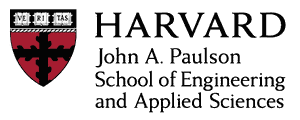

# CS1090A Introduction to Data Science

### Section 10 — Decision Trees

In [ ]:
# Provided — setup. On Colab this fetches the data files this notebook needs.
# Everywhere else it does nothing except confirm they are already here.
#
# Generated at publish time; see utils/inject_colab_bootstrap.py. Editing this cell
# in the public repo is wasted work -- the next publish overwrites it.
import os
import shutil
import subprocess
import sys

_REPO    = "https://github.com/Harvard-CS1090/2026-CS1090A-public"
_REF     = "sec10-2026"
_SECTION = "sec10"

_DIRNAME = _REPO.rstrip("/").split("/")[-1].removesuffix(".git")

if os.path.isdir("data"):
    print(f"data/ is present -- nothing to fetch.")
elif "google.colab" not in sys.modules:
    raise RuntimeError(
        "This notebook reads its inputs from a data/ folder, which is not here.\n"
        "It does not fetch them from the live web -- that is deliberate, and Part 1\n"
        "explains why.\n\n"
        "Fix: get the whole folder, not just the notebook --\n"
        f"    git clone --branch {_REF} {_REPO}\n"
        f"    cd {_DIRNAME}/{_SECTION}\n"
        "    jupyter lab\n\n"
        "Then open this notebook from in there. (On Colab, this cell fetches it for you.)"
    )
else:
    print("Colab detected, no data/ -- fetching it once...")
    _tmp = "/content/_cs1090a_materials"
    if not os.path.isdir(_tmp):
        _r = subprocess.run(
            ["git", "clone", "--depth", "1", "--branch", _REF, _REPO, _tmp],
            capture_output=True, text=True,
        )
        if _r.returncode != 0:
            raise RuntimeError(
                f"Could not download the data files from {_REPO} (ref {_REF}).\n\n"
                f"git said: {_r.stderr.strip().splitlines()[-1] if _r.stderr.strip() else 'no output'}\n\n"
                "This is not something you did wrong. Post on Ed with this message and\n"
                "a TF will sort it out; meanwhile the section notebook will not run here."
            )
    _dir = os.path.join(_tmp, _SECTION)
    _src = os.path.join(_dir, "data")
    if not os.path.isdir(_src):
        raise RuntimeError(
            f"Cloned {_REPO} at {_REF} but found no {_SECTION}/data in it.\n"
            "The published bundle is incomplete -- please report this on Ed."
        )
    shutil.copytree(_src, "data")

    # Sibling modules too, not just data/. Section 1 does `from section_helpers import
    # Recorded`; fetching data/ alone leaves that import failing three cells later,
    # which reads as "the notebook is broken" rather than "setup was incomplete".
    _mods = [f for f in os.listdir(_dir) if f.endswith(".py")]
    for _m in _mods:
        shutil.copy(os.path.join(_dir, _m), _m)

    print(f"data/ ready ({len(os.listdir('data'))} entries)"
          + (f", plus {', '.join(sorted(_mods))}." if _mods else "."))


<div style="background:#E8F1FF; border-left:6px solid #2563EB; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">🎯 Objectives — what you should be able to do by the end</div>
<div>
<ul>
<li>Compute the Gini impurity of a region and the size-weighted impurity of a split, by hand and in code.</li>
<li>Find the best split by trying every predictor and every candidate threshold, and explain why the search is called greedy.</li>
<li>Build a small decision tree from scratch by repeating that search inside each region.</li>
<li>Classify a new observation by traversing a tree from the root to a leaf, and read a predicted probability from the leaf.</li>
<li>Fit the same tree with scikit-learn, and control its size with stopping conditions chosen by cross-validation.</li>
<li>Compare a tree with logistic regression and k-nearest neighbors on the same data, and use the errors each model makes to explain what each one is good at.</li>
</ul>
</div>
</div>

**Colored boxes:** 🤔 commit to a prediction before running the code · 🏋️ write code (look for `# your code here`) · 💬 stop running cells and discuss · ⭐ the point of the exercise · 🧠 what to carry out of the room · 🔍 an appendix item to work through on your own afterward.

A **decision tree** classifies an observation by asking a sequence of yes/no questions about its
predictors, such as "is the flipper length at most 206.5 mm?". The first question is the **root
node**. Each answer sends the observation down one branch to the next question (an **internal
node**), and the last question lands it in a **leaf node**, which predicts a class. Following the
questions from the root to a leaf is called **traversing** the tree.

The section has four parts:

1. **Part A** builds a tree by hand. We start with twelve penguins, find the best first split, then the second, and then write a function that does this for any dataset.
2. **Part B** uses the tree to make predictions, by traversing it from the root to a leaf.
3. **Part C** fits the same tree with scikit-learn and shows how to stop a tree from growing too large.
4. **Part D** is a small project: predict a penguin's species with a tree, logistic regression and k-nearest neighbors, and use the errors each model makes to understand when a tree is a good choice.

**The data.** We use the Palmer penguins from Sections 3 and 6: 333 penguins of three species
(Adelie, Chinstrap and Gentoo) from three islands, with bill length, bill depth, flipper length,
body mass and sex recorded for each.

## Setup

In [ ]:
# Libraries used in this section
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, f1_score, recall_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, export_text, plot_tree

sns.set_theme(style="whitegrid", context="notebook")
SPECIES_COLORS = {"Adelie": "#D97706", "Chinstrap": "#7E22CE", "Gentoo": "#0F766E"}

In [ ]:
# The penguins with every column recorded
penguins = pd.read_csv("data/penguins.csv").dropna().reset_index(drop=True)
print(f"{len(penguins)} penguins; per species: {penguins['species'].value_counts().to_dict()}")
penguins.head(3)

## Part A. Building a tree by hand

To build a tree we need four things, and this part writes each one in turn:

1. a number that says how mixed the species are inside a group of penguins (the **impurity**);
2. a score for one candidate split, computed from the impurity of the two groups it creates;
3. a search over every candidate split, which keeps the one with the best score;
4. a way to repeat the search inside each new group, until the groups are pure or we decide to stop.

### Twelve penguins and two predictors

We start with twelve penguins, four of each species, and two predictors: bill length and flipper
length. That is small enough to check every number by hand.

In [ ]:
# Four penguins of each species, with two predictors
two = ["bill_length_mm", "flipper_length_mm"]
mini = penguins.groupby("species").sample(4, random_state=49)[["species"] + two]
mini

In [ ]:
# The twelve penguins in the predictor space
fig, ax = plt.subplots(figsize=(6.5, 5))
for species, color in SPECIES_COLORS.items():
    rows = mini["species"] == species
    ax.scatter(mini.loc[rows, "bill_length_mm"], mini.loc[rows, "flipper_length_mm"], s=70, color=color, label=species)
ax.set(xlabel="bill length (mm)", ylabel="flipper length (mm)", title="twelve penguins")
ax.legend()
plt.show()

<div style="background:#FFF7CC; border-left:6px solid #D97706; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">🤔 Predict</div>
<div>
A split is a single question about one predictor: a vertical line (a threshold on bill length) or
a horizontal line (a threshold on flipper length). If you could draw only one such line, which
would you draw so that each side is as close as possible to a single species?
</div>
</div>

### Measuring how mixed a group is: the Gini impurity

Write $\Psi(k \mid R)$ for the proportion of the penguins in a group (a **region**) $R$ that belong
to species $k$. The **Gini impurity** of the region is

$$\text{Gini}(R) = 1 - \sum_{k=1}^{K} \Psi(k \mid R)^2 .$$

It is 0 when every penguin in the region has the same species; such a region is **pure**. It is
largest when the species are equally mixed.

**By hand, for all twelve penguins:** each species is $4/12 = 1/3$ of the group, so
$\text{Gini} = 1 - 3 \times (1/3)^2 = 1 - 1/3 \approx 0.667$. For the four Gentoo penguins alone,
the only proportion is 1, so $\text{Gini} = 1 - 1^2 = 0$.

<div style="background:#E9F8EE; border-left:6px solid #16A34A; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">🏋️ Exercise 1: the Gini impurity (3 min)</div>
<div>
Complete <code style="background:rgba(0,0,0,0.06); color:#1F2937;">gini(labels)</code>. It receives the species of the penguins in one region and returns
one minus the sum of the squared class proportions. <code style="background:rgba(0,0,0,0.06); color:#1F2937;">pd.Series(labels).value_counts(normalize=True)</code>
gives the proportions. The cell after it checks your function against the two hand computations above.
</div>
</div>

In [ ]:
# Gini impurity of the class labels in one region
def gini(labels):
    # your code here
    proportions = ...      # the share of each class among the labels
    return 1 - ...         # one minus the sum of the squared proportions


In [ ]:
# Check: all twelve penguins (expect 0.667), the Gentoo penguins only (expect 0), Adelie and Chinstrap (expect 0.5)
print(f"all twelve:            {gini(mini['species']):.3f}")
print(f"Gentoo only:           {gini(mini.loc[mini['species'] == 'Gentoo', 'species']):.3f}")
print(f"Adelie and Chinstrap:  {gini(mini.loc[mini['species'] != 'Gentoo', 'species']):.3f}")

### Scoring one split

A split chooses a predictor $p$ and a threshold $t_p$. Penguins with $x_p \le t_p$ go to the left
region $R_1$ and the rest to the right region $R_2$. The split's score is the average impurity of
the two regions, each weighted by its share of the penguins:

$$\text{score} = \frac{N_1}{N}\,\text{Gini}(R_1) + \frac{N_2}{N}\,\text{Gini}(R_2),$$

where $N_1$ and $N_2$ are the numbers of penguins in the two regions and $N = N_1 + N_2$. Lower is
better: a score of 0 means both regions are pure.

**By hand, for "flipper length $\le$ 206.5":** the left region holds the 4 Adelie and 4 Chinstrap
penguins (Gini 0.5) and the right region the 4 Gentoo penguins (Gini 0). The score is
$\frac{8}{12} \times 0.5 + \frac{4}{12} \times 0 \approx 0.333$, down from 0.667 before the split.

**By hand, for "bill length $\le$ 43.95":** the left region holds the 4 Adelie penguins and one
Gentoo penguin with a short bill (Gini $1 - 0.8^2 - 0.2^2 = 0.32$), and the right region holds 4
Chinstrap and 3 Gentoo (Gini $1 - (4/7)^2 - (3/7)^2 \approx 0.490$). The score is
$\frac{5}{12} \times 0.32 + \frac{7}{12} \times 0.490 \approx 0.419$, so the flipper split is better.

In [ ]:
# Size-weighted Gini of the two regions created by `predictor <= threshold`
def split_score(data, predictor, threshold, target="species"):
    left = data.loc[data[predictor] <= threshold, target]
    right = data.loc[data[predictor] > threshold, target]
    n = len(data)
    return len(left) / n * gini(left) + len(right) / n * gini(right)

print(f"flipper_length_mm <= 206.5:  {split_score(mini, 'flipper_length_mm', 206.5):.3f}")
print(f"bill_length_mm <= 43.95:     {split_score(mini, 'bill_length_mm', 43.95):.3f}")

### Which thresholds to try

On the twelve penguins, any threshold between two neighboring values of a predictor sends exactly
the same penguins left and right, so it gives the same score. It is therefore enough to try one
threshold in each gap: the **midpoint** between consecutive distinct values. scikit-learn uses the
same midpoints, which is why its thresholds end in .5 or .05 here.

In [ ]:
# Candidate thresholds: the midpoints between consecutive distinct values of a predictor
def candidate_thresholds(values):
    distinct = np.unique(values)
    return (distinct[:-1] + distinct[1:]) / 2

print("flipper lengths:      ", np.unique(mini["flipper_length_mm"]))
print("candidate thresholds: ", candidate_thresholds(mini["flipper_length_mm"]))

<div style="background:#E9F8EE; border-left:6px solid #16A34A; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">🏋️ Exercise 2: find the best split (5 min)</div>
<div>
Complete <code style="background:rgba(0,0,0,0.06); color:#1F2937;">best_split(data, predictors)</code>. It tries every predictor in <code style="background:rgba(0,0,0,0.06); color:#1F2937;">predictors</code> and
every candidate threshold of that predictor, computes <code style="background:rgba(0,0,0,0.06); color:#1F2937;">split_score</code> for each, and returns the
best one as a tuple <code style="background:rgba(0,0,0,0.06); color:#1F2937;">(score, predictor, threshold)</code>. The variable <code style="background:rgba(0,0,0,0.06); color:#1F2937;">best</code> holds the best
split found so far; replace it whenever a split has a lower score. On the twelve penguins the next cell
should print the flipper split with score 0.333.
</div>
</div>

In [ ]:
# The split with the lowest size-weighted Gini, over every predictor and candidate threshold
def best_split(data, predictors, target="species"):
    best = None                                     # (score, predictor, threshold) of the best split so far
    for predictor in predictors:
        for threshold in candidate_thresholds(data[predictor]):
            # your code here
            score = ...                           # the size-weighted Gini of this split
            if best is None or ...:               # keep it if it is the lowest so far
                best = ...
    return best

first_score, first_predictor, first_threshold = best_split(mini, two)
print(f"best first split: {first_predictor} <= {first_threshold}   (score {first_score:.3f})")

In [ ]:
# The score of every candidate first split, for each predictor
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for predictor, ax in zip(two, axes):
    thresholds = candidate_thresholds(mini[predictor])
    ax.plot(thresholds, [split_score(mini, predictor, t) for t in thresholds], marker="o", color="#4B5563")
    ax.axhline(gini(mini["species"]), color="grey", linestyle="--", label="Gini before splitting")
    ax.set(xlabel=f"threshold on {predictor}", title=f"splits on {predictor}")
axes[0].set_ylabel("size-weighted Gini after the split")
axes[0].legend()
plt.tight_layout()
plt.show()

Every point is one candidate split. The lowest point on either panel is the flipper split at
206.5, with score 0.333. The best bill-length split only reaches 0.419, because one Gentoo penguin
has a short bill and lands on the Adelie side.

### The second split

The right region (flipper length above 206.5) holds only Gentoo penguins, so it is pure and we stop
there. The left region still mixes Adelie and Chinstrap, so we run **the same search again, using
only the penguins in that region**.

In [ ]:
# Split the twelve penguins at the first split, then search again inside the mixed region
left_region = mini[mini[first_predictor] <= first_threshold]
right_region = mini[mini[first_predictor] > first_threshold]
print("left region: ", left_region["species"].value_counts().to_dict())
print("right region:", right_region["species"].value_counts().to_dict())

second_score, second_predictor, second_threshold = best_split(left_region, two)
print(f"best split of the left region: {second_predictor} <= {second_threshold}   (score {second_score:.3f})")

The second split, bill length $\le$ 43.95, separates the Adelie penguins from the Chinstrap ones
perfectly (score 0). Every region is now pure, so the tree is finished. Written as questions:

```
flipper_length_mm <= 206.5 ?
├── yes: bill_length_mm <= 43.95 ?
│        ├── yes: Adelie
│        └── no:  Chinstrap
└── no:  Gentoo
```

The figure shows the same tree as lines in the predictor space. Each split cuts one existing
region in two, so every region is a rectangle.

In [ ]:
# The two splits drawn as boundaries: a horizontal line, then a vertical line below it
fig, ax = plt.subplots(figsize=(6.5, 5))
for species, color in SPECIES_COLORS.items():
    rows = mini["species"] == species
    ax.scatter(mini.loc[rows, "bill_length_mm"], mini.loc[rows, "flipper_length_mm"], s=70, color=color, label=species)
x_low, x_high = 34, 55
ax.plot([x_low, x_high], [first_threshold] * 2, color="black", linewidth=2, label="split 1")
ax.plot([second_threshold] * 2, [186, first_threshold], color="black", linestyle="--", linewidth=2, label="split 2")
ax.text(36, 200, "Adelie", fontsize=12); ax.text(47, 189, "Chinstrap", fontsize=12); ax.text(36, 220, "Gentoo", fontsize=12)
ax.set(xlim=(x_low, x_high), ylim=(186, 226), xlabel="bill length (mm)", ylabel="flipper length (mm)",
       title="the tree with two splits")
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1))
plt.show()

<div style="background:#FDECEC; border-left:6px solid #DC2626; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">💬 Discuss — Checkpoint 1: what the search compares</div>
<div>
<ol>
<li>Bill length alone separates the Adelie penguins from everyone else, except one Gentoo. Why did the tree still start with flipper length?</li>
<li>Suppose the score were the plain average of the two regions' Gini values, without the weights $N_1/N$ and $N_2/N$. Which kind of split would that favor? (Think of a split that puts a single penguin on one side.)</li>
</ol>
</div>
</div>

### Other ways to measure impurity

Gini is not the only impurity. Two others appear in lecture and in scikit-learn:

- **Entropy:** $\text{Entropy}(R) = -\sum_k \Psi(k \mid R) \log_2 \Psi(k \mid R)$, used with `criterion="entropy"`. It is also 0 for a pure region, and for three equally mixed species it is $\log_2 3 \approx 1.585$.
- **Classification error:** $\text{Error}(R) = 1 - \max_k \Psi(k \mid R)$, the share of the region that the majority class gets wrong.

The cell below scores our two candidate first splits with all three.

In [ ]:
# Entropy and classification error, and the two candidate first splits scored with each impurity
def entropy(labels):
    proportions = pd.Series(labels).value_counts(normalize=True)
    return -(proportions * np.log2(proportions)).sum() + 0.0   # + 0.0 turns -0.0 into 0.0

def class_error(labels):
    return 1 - pd.Series(labels).value_counts(normalize=True).max()

def weighted_impurity(data, predictor, threshold, impurity, target="species"):
    left = data.loc[data[predictor] <= threshold, target]
    right = data.loc[data[predictor] > threshold, target]
    return len(left) / len(data) * impurity(left) + len(right) / len(data) * impurity(right)

pd.DataFrame({name: [weighted_impurity(mini, "flipper_length_mm", 206.5, f),
                     weighted_impurity(mini, "bill_length_mm", 43.95, f)]
              for name, f in [("Gini", gini), ("entropy", entropy), ("classification error", class_error)]},
             index=["flipper_length_mm <= 206.5", "bill_length_mm <= 43.95"]).round(3)

<div style="background:#F3E8FF; border-left:6px solid #7E22CE; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">⭐ Insight</div>
<div>
Gini and entropy both give the flipper split the lower score. Classification error gives both
splits the same score, 0.333, because in each case 4 of the 12 penguins end up in a region whose
majority class is wrong for them. It cannot see that the flipper split leaves one region
<em>perfectly</em> pure. This is why trees are grown with Gini or entropy: they reward a split that
makes a region purer even when the number of misclassified points stays the same.
</div>
</div>

### From two splits to any tree: a recursive function

We built the mini-tree by repeating one step: find the best split of a region, divide it, and do
the same inside each half. A function that calls itself on smaller pieces of the problem is
called **recursive**. `build_tree` below follows these steps, numbered in the code:

1. **Stop** if the region is pure, or if the tree has reached its maximum depth. Then the region becomes a **leaf**, which stores the number of penguins of each species and predicts the most common one.
2. **Find** the best split of the region with `best_split`.
3. **Divide** the region into the penguins that satisfy the split and those that do not.
4. **Build** a tree inside each half, by calling `build_tree` again with depth one larger.

The search is **greedy**: each split is the best one available at that moment, and the function
never goes back to change an earlier split. The tree is stored as nested dictionaries: an internal
node holds a predictor, a threshold and two subtrees; a leaf holds a class and its counts.

In [ ]:
# A decision tree built recursively from best_split, stored as nested dictionaries
def build_tree(data, predictors, depth=0, max_depth=3, target="species"):
    counts = data[target].value_counts().sort_index()
    leaf = {"class": counts.idxmax(), "counts": counts.to_dict()}
    # 1. stop: the region is pure, or the tree is as deep as allowed
    if gini(data[target]) == 0 or depth == max_depth:
        return leaf
    # 2. find the best split of this region
    split = best_split(data, predictors, target)
    if split is None:                               # every penguin has the same predictor values
        return leaf
    _, predictor, threshold = split
    # 3. divide the region
    left = data[data[predictor] <= threshold]
    right = data[data[predictor] > threshold]
    # 4. build a tree inside each half
    return {"predictor": predictor, "threshold": threshold,
            "left": build_tree(left, predictors, depth + 1, max_depth, target),
            "right": build_tree(right, predictors, depth + 1, max_depth, target)}


def show(node, indent=""):
    # Print a tree in the layout of scikit-learn's export_text
    if "class" in node:
        print(f"{indent}class {node['class']}   counts {node['counts']}")
        return
    print(f"{indent}{node['predictor']} <= {node['threshold']:.2f}")
    show(node["left"], indent + "|   ")
    print(f"{indent}{node['predictor']} >  {node['threshold']:.2f}")
    show(node["right"], indent + "|   ")

In [ ]:
# The function rebuilds the mini-tree from the twelve penguins
mini_tree = build_tree(mini, two)
show(mini_tree)

That is the tree we built by hand. The same function works on any number of penguins. On all 333
penguins the regions are not pure after two splits, so the function keeps going until it reaches
`max_depth=3`.

In [ ]:
# The same function on all 333 penguins, stopped at depth 3
full_tree = build_tree(penguins, two, max_depth=3)
show(full_tree)

## Part B. Making predictions: traversing the tree

To classify a penguin, start at the root and answer its question. If the answer is yes (the
penguin's value is at most the threshold), go to the left subtree; if no, go to the right. Repeat
until you reach a leaf, and predict the leaf's class. The tree only ever asks about the predictors
in its nodes, so a penguin needs a value for those and nothing else.

<div style="background:#E9F8EE; border-left:6px solid #16A34A; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">🏋️ Exercise 3: traverse the tree (4 min)</div>
<div>
Complete <code style="background:rgba(0,0,0,0.06); color:#1F2937;">predict_one(node, penguin)</code>. <code style="background:rgba(0,0,0,0.06); color:#1F2937;">penguin</code> is one row: a pandas Series whose
labels are the predictor names. While <code style="background:rgba(0,0,0,0.06); color:#1F2937;">node</code> is an internal node (it has no <code style="background:rgba(0,0,0,0.06); color:#1F2937;">"class"</code>
key), move to <code style="background:rgba(0,0,0,0.06); color:#1F2937;">node["left"]</code> if <code style="background:rgba(0,0,0,0.06); color:#1F2937;">penguin[node["predictor"]] <= node["threshold"]</code> and
to <code style="background:rgba(0,0,0,0.06); color:#1F2937;">node["right"]</code> otherwise. When you reach a leaf, return its class.
</div>
</div>

In [ ]:
# Walk one penguin from the root to a leaf and return the leaf's class
def predict_one(node, penguin):
    # your code here
    while ...:                                    # until node is a leaf (a dict with a "class" key)
        if ...:                                   # the penguin's value is at most the node's threshold
            node = ...
        else:
            node = ...
    return ...


The next cell walks a new penguin through the mini-tree and prints every question on the way, so
you can follow the path by hand. The penguin has a bill length of 46.0 mm and a flipper length of
200 mm.

In [ ]:
# Print the questions a penguin answers on its way to a leaf
def show_path(node, penguin):
    while "class" not in node:
        value, threshold = penguin[node["predictor"]], node["threshold"]
        answer = "yes, go left" if value <= threshold else "no, go right"
        print(f"is {node['predictor']} = {value} <= {threshold}?  {answer}")
        node = node["left"] if value <= threshold else node["right"]
    print(f"leaf: predict {node['class']}   (training counts in this leaf: {node['counts']})")

new_penguin = pd.Series({"bill_length_mm": 46.0, "flipper_length_mm": 200.0})
show_path(mini_tree, new_penguin)
print("predict_one gives:", predict_one(mini_tree, new_penguin))

### How well does the mini-tree do on penguins it has not seen?

The mini-tree was built from 12 penguins. The other 321 penguins were never used to build it, so
they are a fair test of how well its two questions work in general.

In [ ]:
# Accuracy of the twelve-penguin tree on the other 321 penguins
others = penguins.drop(index=mini.index)
predictions = others.apply(lambda row: predict_one(mini_tree, row), axis=1)
print(f"accuracy on the {len(others)} other penguins: {(predictions == others['species']).mean():.3f}")

Two questions learned from twelve penguins classify about 94% of the other penguins correctly.
The thresholds are not exactly where they would be with more data, and the errors are penguins that
fall on the wrong side of one of them.

### A probability from a leaf

A leaf also gives a **predicted probability** for each class: the share of the training penguins in
that leaf that belong to the class. scikit-learn's `predict_proba` does exactly this.

In [ ]:
# The class shares in the leaf a penguin lands in, for the depth-3 tree on all 333 penguins
def predict_proba_one(node, penguin):
    while "class" not in node:
        node = node["left"] if penguin[node["predictor"]] <= node["threshold"] else node["right"]
    total = sum(node["counts"].values())
    return {species: round(count / total, 3) for species, count in node["counts"].items()}

for bill, flipper in [(40.0, 200.0), (44.0, 200.0), (50.0, 200.0)]:
    penguin = pd.Series({"bill_length_mm": bill, "flipper_length_mm": flipper})
    print(f"bill {bill}, flipper {flipper}:", predict_proba_one(full_tree, penguin))

<div style="background:#FDECEC; border-left:6px solid #DC2626; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">💬 Discuss — Checkpoint 2: reading a prediction</div>
<div>
<ol>
<li>What is the largest number of questions the depth-3 tree asks before it predicts? Does every penguin answer the same number of questions?</li>
<li>The mini-tree's leaves are all pure, so every probability it gives is 0 or 1. Should we believe a probability of 1 from a leaf that holds four training penguins?</li>
</ol>
</div>
</div>

## Part C. Decision trees in scikit-learn, and when to stop growing

### The same tree with `DecisionTreeClassifier`

scikit-learn's `DecisionTreeClassifier` runs the same greedy search with the Gini impurity by
default. `export_text` prints the fitted tree; `show_weights=True` adds the number of training
penguins of each class in each leaf (in alphabetical order: Adelie, Chinstrap, Gentoo).

In [ ]:
# scikit-learn's tree on the twelve penguins
sk_mini = DecisionTreeClassifier(random_state=0).fit(mini[two], mini["species"])
print(export_text(sk_mini, feature_names=two, show_weights=True))

In [ ]:
# On all 333 penguins at depth 3: the share of penguins where our tree and scikit-learn's agree
sk_full = DecisionTreeClassifier(max_depth=3, random_state=0).fit(penguins[two], penguins["species"])
ours = penguins.apply(lambda row: predict_one(full_tree, row), axis=1)
print(f"share of penguins where the two trees agree: {(ours == sk_full.predict(penguins[two])).mean():.3f}")

The two trees make the same prediction for every penguin: the code we wrote in Part A is what
scikit-learn does. `plot_tree` draws the fitted tree. Each box shows the question, the Gini impurity
of the node, the number of penguins that reach it (`samples`), the count of each species (`value`)
and the majority class. Penguins that satisfy the condition go left (`True`).

In [ ]:
# The depth-3 tree on all penguins, drawn
fig, ax = plt.subplots(figsize=(18, 7))
plot_tree(sk_full, feature_names=two, class_names=list(sk_full.classes_), filled=True, fontsize=9, ax=ax)
plt.show()

### A harder question: male or female?

Species is easy to predict from these measurements. To see why a tree must be stopped, we switch to
a question where the classes overlap: is a penguin male or female, given its four body
measurements? Males are larger on average, but a large female of a small species can be bigger than
a male of the same species, so no set of rectangles separates the two classes perfectly.

From here on every model is evaluated with five-fold cross-validation, and the same folds are used
every time.

In [ ]:
# Predict sex from the four body measurements; five stratified folds, reused below
measurements = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
X_sex, y_sex = penguins[measurements], penguins["sex"]
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
print(f"share female: {(y_sex == 'Female').mean():.3f}")

<div style="background:#FFF7CC; border-left:6px solid #D97706; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">🤔 Predict</div>
<div>
We fit a tree with no limit on its size. What will its training accuracy be? Will its
cross-validated accuracy be close to that?
</div>
</div>

In [ ]:
# A tree with no limit on its size: training accuracy, cross-validated accuracy, number of leaves
unlimited = DecisionTreeClassifier(random_state=0)
cv_unlimited = cross_val_score(unlimited, X_sex, y_sex, cv=skf).mean()
unlimited.fit(X_sex, y_sex)
print(f"training accuracy {unlimited.score(X_sex, y_sex):.3f}, cross-validated accuracy {cv_unlimited:.3f}, "
      f"{unlimited.get_n_leaves()} leaves, depth {unlimited.get_depth()}")

The tree is perfect on the penguins it was trained on and correct for only about 87% of penguins
it has not seen. Many of its 41 leaves hold one or two penguins: it has fitted individual
penguins, which is **overfitting**.

### The stopping conditions

Our `build_tree` stopped at a pure region or at `max_depth`. scikit-learn has several more
**stopping conditions**; each one stops the tree from splitting a region further:

| Argument | Stops splitting when… |
|---|---|
| `max_depth` | the path from the root has reached this many questions |
| `min_samples_leaf` | a split would leave fewer than this many penguins in one of the two new regions |
| `max_leaf_nodes` | the tree already has this many leaves |
| `min_impurity_decrease` | the best split would lower the size-weighted impurity by less than this amount |

The cell below tries a few values of each and reports training accuracy, cross-validated accuracy
and tree size.

In [ ]:
# Each stopping condition at a few values: training and cross-validated accuracy, leaves and depth
settings = [("max_depth", [2, 3, 5]), ("min_samples_leaf", [5, 20]),
            ("max_leaf_nodes", [4, 8]), ("min_impurity_decrease", [0.005, 0.02])]
rows = []
for name, values in settings:
    for value in values:
        model = DecisionTreeClassifier(random_state=0, **{name: value})
        cv = cross_val_score(model, X_sex, y_sex, cv=skf).mean()
        model.fit(X_sex, y_sex)
        rows.append({"setting": f"{name}={value}", "training": model.score(X_sex, y_sex),
                     "cross-validated": cv, "leaves": model.get_n_leaves(), "depth": model.get_depth()})
pd.DataFrame(rows).set_index("setting").round(3)

In [ ]:
# Training and cross-validated accuracy against max_depth
depths = [1, 2, 3, 4, 5, 6, 8, 10]
train_acc, cv_acc = [], []
for depth in depths:
    model = DecisionTreeClassifier(max_depth=depth, random_state=0)
    cv_acc.append(cross_val_score(model, X_sex, y_sex, cv=skf).mean())
    train_acc.append(model.fit(X_sex, y_sex).score(X_sex, y_sex))
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(depths, train_acc, marker="o", color="#4B5563", label="training")
ax.plot(depths, cv_acc, marker="o", color="#DC2626", label="cross-validated")
ax.set(xlabel="max_depth", ylabel="accuracy", title="predicting sex: accuracy against tree depth")
ax.legend()
plt.show()

Training accuracy rises with every extra level. Cross-validated accuracy rises until depth 3 and
then falls: the deeper splits fit the training penguins, not penguins in general. So the stopping
condition must be chosen by cross-validation, never by training accuracy. `GridSearchCV` does that
search for us, here over two stopping conditions at once.

In [ ]:
# Choose max_depth and min_samples_leaf together by cross-validated accuracy
search = GridSearchCV(DecisionTreeClassifier(random_state=0),
                      {"max_depth": [2, 3, 4, 5, 6, 8, None], "min_samples_leaf": [1, 5, 10, 20]},
                      cv=skf).fit(X_sex, y_sex)
print(f"best setting {search.best_params_}, cross-validated accuracy {search.best_score_:.3f}")

In [ ]:
# The chosen tree, drawn
sex_tree = search.best_estimator_
fig, ax = plt.subplots(figsize=(20, 7))
plot_tree(sex_tree, feature_names=measurements, class_names=list(sex_tree.classes_), filled=True, fontsize=9, ax=ax)
plt.show()

<div style="background:#FDECEC; border-left:6px solid #DC2626; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">💬 Discuss — Checkpoint 3: the first splits in words</div>
<div>
<ol>
<li>Write the root split as a sentence about penguins, not about column names.</li>
<li>On the right branch (heavier penguins), the next question is about bill depth, not body mass. Use the species means below to explain what that split is really detecting, and why the tree then asks about body mass again with a different threshold.</li>
</ol>
</div>
</div>

In [ ]:
# Mean measurements by species, for Checkpoint 3
penguins.groupby("species")[measurements].mean().round(1)

## Part D. A small project: which model for penguin species?

A field biologist wants a model that identifies a penguin's species from measurements taken on the
beach. We compare four models that you have seen this semester on the same data and the same
folds, then look at the penguins each model gets wrong. The question is not only *which model has
the highest accuracy*, but *why each model makes the errors it makes*, and what that says about
when to use a tree.

### The data for the project

The predictors are the four measurements plus the island and the sex. Island and sex are
categories, so we **one-hot encode** them: one 0/1 column per value. A tree splits a one-hot column
with a question like `island_Dream <= 0.5`, which means "is this penguin *not* from Dream?".

In [ ]:
# Predictors: four measurements and one-hot island and sex; the outcome is the species
X = pd.get_dummies(penguins[measurements + ["island", "sex"]], dtype=int)
y = penguins["species"]
print(list(X.columns))
print(f"standard deviation of each measurement: {X[measurements].std().round(1).to_dict()}")

Notice the very different scales. Body mass is in grams and varies by about 800, while bill depth
is in millimeters and varies by about 2. Keep this in mind for k-nearest neighbors.

### Four models

- **Logistic regression**, after **standardizing** each predictor (subtracting its mean and dividing by its standard deviation, so that every column has standard deviation 1).
- **k-nearest neighbors** with $k = 5$ on the raw columns: predict the most common species among the 5 penguins at the smallest distance.
- **k-nearest neighbors** with $k = 5$ after standardizing.
- **A decision tree**, with `max_depth` chosen by cross-validation.

We compare them with **out-of-fold** predictions: each penguin's prediction comes from the model
fitted on the four folds that did not contain it (`cross_val_predict`). Every penguin then has one
prediction from a model that never saw it, which lets us look at individual errors. Besides
accuracy we report the **recall** of each species (the share of that species predicted correctly)
and **macro-F1**, the average over the three species of the F1 score
($2 \cdot \text{precision} \cdot \text{recall} / (\text{precision} + \text{recall})$), so that the
smallest species, Chinstrap, counts as much as the others.

<div style="background:#FFF7CC; border-left:6px solid #D97706; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">🤔 Predict</div>
<div>
Rank the four models from the highest to the lowest accuracy. Which one do you expect to do much
worse than the others, and why?
</div>
</div>

In [ ]:
# Choose the tree's max_depth by cross-validated macro-F1
depth_search = GridSearchCV(DecisionTreeClassifier(random_state=0), {"max_depth": [1, 2, 3, 4, 5, 6, 8, None]},
                            scoring="f1_macro", cv=skf).fit(X, y)
best_depth = depth_search.best_params_["max_depth"]
print(f"chosen max_depth: {best_depth}")

In [ ]:
# Out-of-fold predictions of the four models, and accuracy, macro-F1 and recall for each species
models = {
    "logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)),
    "kNN, raw columns": KNeighborsClassifier(n_neighbors=5),
    "kNN, standardized": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    "decision tree": DecisionTreeClassifier(max_depth=best_depth, random_state=0),
}
oof = {name: cross_val_predict(model, X, y, cv=skf) for name, model in models.items()}
species_names = sorted(y.unique())
comparison = pd.DataFrame({
    name: {"accuracy": (pred == y).mean(), "macro-F1": f1_score(y, pred, average="macro"),
           **{f"recall, {s}": r for s, r in zip(species_names, recall_score(y, pred, average=None))},
           "errors": int((pred != y).sum())}
    for name, pred in oof.items()}).T
comparison.round(3)

Logistic regression has the highest accuracy, with 2 errors out of 333. Standardized kNN and the
tree are close behind. kNN on the raw columns is far behind, and its recall for Chinstrap is only
about one in three. The tree is **not** the most accurate model here. The rest of this part asks
why each model makes its errors.

### Error analysis 1: k-nearest neighbors on raw columns

In [ ]:
# Where kNN on raw columns goes wrong: its confusion matrix, and the species' mean body mass
def confusion_table(pred):
    return pd.DataFrame(confusion_matrix(y, pred, labels=species_names),
                        index=[f"true {s}" for s in species_names], columns=[f"predicted {s}" for s in species_names])

print(confusion_table(oof["kNN, raw columns"]), end="\n\n")
print("mean body mass (g):", penguins.groupby("species")["body_mass_g"].mean().round(0).to_dict())

Most of its errors are Chinstrap penguins predicted as Adelie. On the raw columns, the distance
between two penguins is almost entirely their difference in body mass, and Adelie and Chinstrap
penguins weigh almost the same (about 3,700 g on average). Their bills differ by about 10 mm, which
is what separates them, but 10 mm counts for as little as 10 g. Standardizing puts every column on
the same scale and fixes this, which is why standardized kNN does well.

A tree does not have this problem, because it never adds up columns: each question compares one
column with a threshold, and changing a column's units only changes the threshold.

<div style="background:#E9F8EE; border-left:6px solid #16A34A; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">🏋️ Exercise 4: a tree does not care about scale (3 min)</div>
<div>
Check the last claim. Compute <code style="background:rgba(0,0,0,0.06); color:#1F2937;">oof_scaled</code>, the out-of-fold predictions of the same tree
(<code style="background:rgba(0,0,0,0.06); color:#1F2937;">max_depth=best_depth, random_state=0</code>) fitted on standardized columns, using
<code style="background:rgba(0,0,0,0.06); color:#1F2937;">make_pipeline(StandardScaler(), ...)</code> and <code style="background:rgba(0,0,0,0.06); color:#1F2937;">cross_val_predict</code> with <code style="background:rgba(0,0,0,0.06); color:#1F2937;">cv=skf</code>.
The cell then prints the share of penguins whose prediction is the same as without standardizing.
</div>
</div>

In [ ]:
# The same tree on standardized columns: do any predictions change?
# your code here
scaled_tree = ...                 # a pipeline: StandardScaler, then the tree
oof_scaled = ...                  # its out-of-fold predictions, folds skf
print(f"share of penguins with the same prediction: {(oof_scaled == oof['decision tree']).mean():.3f}")
changed = oof_scaled != oof["decision tree"]
penguins.loc[changed, ["species", "island"] + measurements]

Standardizing changes the prediction for at most a penguin or two, and the cell lists them. In our
run it is one Chinstrap penguin whose bill length is exactly 42.4 mm. One of the tree's splits
asks "bill length at most 42.4?", so this penguin sits exactly on the threshold. On the raw scale it
satisfies the condition and goes left. After standardizing, the threshold and the penguin's value
are computed with slightly different rounding in the last decimal places, and the penguin lands on
the other side. Apart from points exactly on a threshold, standardizing a column only relabels its
thresholds, so the tree makes the same splits and the same predictions.

### Error analysis 2: the tree against logistic regression

Now the closer comparison. The next cell lists the penguins the tree gets wrong, with what
logistic regression predicted for the same penguin.

In [ ]:
# The penguins the tree misclassifies out of fold, with logistic regression's prediction beside them
tree_wrong = oof["decision tree"] != y
errors = penguins.loc[tree_wrong, ["species", "island", "sex"] + measurements].copy()
errors["tree predicts"] = oof["decision tree"][tree_wrong]
errors["logistic regression predicts"] = oof["logistic regression"][tree_wrong]
errors

To see *why* the tree got one of these penguins wrong, we can traverse the tree that made the
prediction, as in Part B. For an out-of-fold prediction that is the tree fitted on the four folds
that did not contain the penguin. scikit-learn stores a fitted tree as arrays rather than
dictionaries, but the walk is the same as `predict_one`.

In [ ]:
# Refit the tree on the folds that did not contain penguin `row`, and print the questions it asks
def show_sklearn_path(row):
    train_rows = next(train for train, test in skf.split(X, y) if row in test)
    model = DecisionTreeClassifier(max_depth=best_depth, random_state=0).fit(X.iloc[train_rows], y.iloc[train_rows])
    t, node, penguin = model.tree_, 0, X.iloc[row]
    while t.children_left[node] != -1:                       # -1 marks a leaf
        name, threshold = X.columns[t.feature[node]], t.threshold[node]
        goes_left = penguin[name] <= threshold
        print(f"is {name} = {penguin[name]} <= {threshold:.2f}?  {'yes, go left' if goes_left else 'no, go right'}")
        node = t.children_left[node] if goes_left else t.children_right[node]
    shares = {s: round(float(v), 2) for s, v in zip(model.classes_, t.value[node][0])}
    print(f"leaf: class shares {shares}, so predict {model.classes_[t.value[node][0].argmax()]}; "
          f"true species: {y.iloc[row]}")

for row in [errors.index[0], errors.index[-1]]:      # the first Adelie error and the last Gentoo error
    print(f"penguin {row}:")
    show_sklearn_path(row)
    print()

In [ ]:
# Bill length against bill depth, with each model's errors circled
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharex=True, sharey=True)
for name, ax in zip(["decision tree", "logistic regression"], axes):
    for species, color in SPECIES_COLORS.items():
        rows = y == species
        ax.scatter(penguins.loc[rows, "bill_length_mm"], penguins.loc[rows, "bill_depth_mm"], s=14, alpha=0.6,
                   color=color, label=species)
    wrong = oof[name] != y
    ax.scatter(penguins.loc[wrong, "bill_length_mm"], penguins.loc[wrong, "bill_depth_mm"], s=160,
               facecolors="none", edgecolors="black", linewidths=1.5, label="misclassified")
    ax.set(xlabel="bill length (mm)", title=f"{name}: {int(wrong.sum())} errors")
axes[0].set_ylabel("bill depth (mm)")
axes[0].legend()
plt.tight_layout()
plt.show()

The tree's Adelie and Chinstrap errors sit where those two species overlap. The two Gentoo
errors look surprising: in this plot they sit inside the Gentoo cloud. They were misclassified
because of a column the plot does not show. Their flippers (207 and 203 mm) are short for a Gentoo
(the Gentoo average is 217 mm), so the first question, about flipper length, sent them to the
Adelie and Chinstrap side of the tree, as the path printed above shows, and no later question
could bring them back. Each question in a tree looks at one column, so a penguin that crosses one
threshold goes down the wrong branch even when its other measurements point to its true species.
Logistic regression
combines all the columns in one weighted sum, so a long bill can be offset by a deep bill. Its
boundaries between species can be diagonal lines, which a tree can only approximate with a
staircase of many small rectangles.

### What the tree offers in exchange: a model you can read

A tree's accuracy is a little lower here, but it can be written down as a short list of rules. The
cell below fits a depth-3 tree on all penguins and prints it.

In [ ]:
# A depth-3 tree on all penguins: its cross-validated accuracy, and its rules
rulebook = DecisionTreeClassifier(max_depth=3, random_state=0)
print(f"cross-validated accuracy: {cross_val_score(rulebook, X, y, cv=skf).mean():.3f}\n")
print(export_text(rulebook.fit(X, y), feature_names=list(X.columns), show_weights=True))

A biologist with no computer can apply these rules on the beach: measure the flipper, then the
bill, and check the island. The rules also match what is known about the birds: Gentoo have the
longest flippers, Chinstrap have long bills, and in this dataset Chinstrap penguins were recorded
only on Dream island (the table below), so "long bill, on Dream" points to Chinstrap.

In [ ]:
# Which species were recorded on which island
pd.crosstab(penguins["species"], penguins["island"])

<div style="background:#FDECEC; border-left:6px solid #DC2626; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">💬 Discuss — Checkpoint 4: when is a tree a good choice?</div>
<div>
<ol>
<li>kNN on raw columns failed and the tree did not, although neither was standardized. Explain the difference in one or two sentences about how each model uses the columns.</li>
<li>Logistic regression made fewer errors than the tree. Use the error plot to explain what logistic regression can do that a tree cannot.</li>
<li>The biologist asks which model to use. What would you recommend, and what would change your answer?</li>
<li>From Part C and Part D, describe a kind of data on which you would expect a tree to beat logistic regression.</li>
</ol>
</div>
</div>

<div style="background:#F3F4F6; border-left:6px solid #4B5563; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">🧠 Takeaways — four things to remember</div>
<div>
<ol>
<li><strong>A tree chooses each split by trying every predictor and every candidate threshold, and keeping the split with the lowest size-weighted impurity.</strong> It then repeats the same search inside each new region and never revisits a split, so the search is greedy and every region is a rectangle. Gini and entropy are used rather than classification error because they reward a split that makes a region purer even when the number of misclassified points does not change.</li>
<li><strong>A tree predicts by traversing it: answer the question at each node, go left on yes and right on no, and predict the leaf's majority class.</strong> The leaf's class shares are its predicted probabilities, and they are only as reliable as the number of training points in the leaf.</li>
<li><strong>A tree with no stopping condition fits its training data perfectly and overfits.</strong> Limit it with <code style="background:rgba(0,0,0,0.06); color:#1F2937;">max_depth</code>, <code style="background:rgba(0,0,0,0.06); color:#1F2937;">min_samples_leaf</code>, <code style="background:rgba(0,0,0,0.06); color:#1F2937;">max_leaf_nodes</code> or <code style="background:rgba(0,0,0,0.06); color:#1F2937;">min_impurity_decrease</code>, and choose the value by cross-validation, never by training accuracy.</li>
<li><strong>A tree compares one column at a time with a threshold, so it needs no scaling and reads as rules, but its boundaries are made of vertical and horizontal pieces.</strong> On the penguins logistic regression was more accurate, because the species are best separated by combining measurements. Compare models on the same folds and read the errors each one makes before choosing.</li>
</ol>
<p><strong>Final check:</strong> a leaf holds 12 training penguins: 9 Adelie and 3 Chinstrap. What is its Gini impurity, what does the tree predict for a new penguin that lands in it, and what probability does it give to Chinstrap?</p>
</div>
</div>

---

## Appendix: things to try later

**Nothing below is expected during section.** Each item is a 🔍 Explore box: the code below it is
provided and runs as-is, and the work is reading the output and answering the questions.

- **A1**: cost-complexity pruning (`ccp_alpha`), another way to control the size of a tree.
- **A2**: regression trees, which predict a number.

### A1. Cost-complexity pruning

<div style="background:#E8F6F3; border-left:6px solid #0F766E; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">🔍 Explore — A1</div>
<div>
<p>Stopping conditions stop a tree while it grows. <strong>Pruning</strong> instead grows the full
tree and then removes the branches that add the least. For a subtree $T$ with $|T|$ leaves the
cost is $C(T) = \text{Error}(T) + \alpha\,|T|$: the <strong>complexity parameter</strong>
$\alpha \ge 0$ charges a fixed amount for every leaf, so a larger $\alpha$ keeps fewer leaves. In
scikit-learn $\alpha$ is <code style="background:rgba(0,0,0,0.06); color:#1F2937;">ccp_alpha</code>,
and $\text{Error}(T)$ is the total Gini impurity of the leaves, each weighted by its share of the
points. The cell refits the Part C sex tree for several values of $\alpha$.</p>
<ol>
<li>How does the number of leaves change as $\alpha$ grows, and where is the cross-validated accuracy highest?</li>
<li>How does the best pruned tree compare with the best tree from Part C's search?</li>
</ol>
</div>
</div>

In [ ]:
# Cross-validated accuracy and number of leaves for several values of ccp_alpha, on the sex question
alpha_rows = []
for alpha in [0, 0.002, 0.005, 0.01, 0.02, 0.05]:
    model = DecisionTreeClassifier(ccp_alpha=alpha, random_state=0)
    alpha_rows.append({"ccp_alpha": alpha, "cross-validated": cross_val_score(model, X_sex, y_sex, cv=skf).mean(),
                       "leaves": model.fit(X_sex, y_sex).get_n_leaves()})
pd.DataFrame(alpha_rows).set_index("ccp_alpha").round(3)

### A2. Regression trees

<div style="background:#E8F6F3; border-left:6px solid #0F766E; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">🔍 Explore — A2</div>
<div>
<p>A <strong>regression tree</strong> predicts a number. Each leaf predicts the mean
$\bar{y}_{R}$ of the training outcomes in its region, and splits are chosen by the size-weighted
mean squared error of the two regions, where
$\text{MSE}(R) = \frac{1}{N_R}\sum_{i \in R} (y_i - \bar{y}_{R})^2$. The cell predicts a penguin's
body mass from its flipper length with trees of depth 1, 3 and 8.</p>
<ol>
<li>What shape is each fitted curve, and why?</li>
<li>What is the depth-8 tree fitting that the depth-3 tree is not?</li>
</ol>
</div>
</div>

In [ ]:
# Regression trees of depth 1, 3 and 8: body mass from flipper length
flipper = penguins[["flipper_length_mm"]]
grid = pd.DataFrame({"flipper_length_mm": np.linspace(flipper.min().iloc[0], flipper.max().iloc[0], 500)})
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for depth, ax in zip([1, 3, 8], axes):
    reg = DecisionTreeRegressor(max_depth=depth, random_state=0).fit(flipper, penguins["body_mass_g"])
    ax.scatter(flipper, penguins["body_mass_g"], s=10, color="#4B5563", alpha=0.5)
    ax.plot(grid, reg.predict(grid), color="#DC2626", linewidth=2)
    ax.set(xlabel="flipper length (mm)", title=f"max_depth={depth}: {reg.get_n_leaves()} leaves")
axes[0].set_ylabel("body mass (g)")
plt.tight_layout()
plt.show()